# 🔐 AI Threat Actor Detection with Random Forest + LSTM
This notebook includes:
- Preprocessing of UNSW-NB15 dataset
- Random Forest classifier
- SHAP (Explainable AI)
- LSTM sequence modeling
- Real-time log simulation with response actions

In [1]:
!pip install shap -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import shap
import pickle
import time
import random

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Embedding
from tensorflow.keras.utils import to_categorical


In [4]:
from google.colab import drive
drive.mount('/content/drive')


df = pd.read_csv("/content/drive/MyDrive/UNSW-NB15-processed.csv")
print("Data Shape:", df.shape)
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data Shape: (82332, 46)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,attack_ttp
0,-1.732030,-0.213727,117,0,4,-0.124455,-0.151816,-0.043684,-0.087369,0.057181,...,-0.477994,-0.090857,-0.090617,-0.203143,-0.640033,-0.644190,-0.10607,Normal,-1.106883,Unknown
1,-1.731988,-0.213728,117,0,4,-0.124455,-0.151816,-0.036308,-0.087369,0.286565,...,-0.477994,-0.090857,-0.090617,-0.203143,-0.640033,-0.644190,-0.10607,Normal,-1.106883,Unknown
2,-1.731946,-0.213729,117,0,4,-0.124455,-0.151816,-0.040351,-0.087369,0.791209,...,-0.390391,-0.090857,-0.090617,-0.203143,-0.640033,-0.554273,-0.10607,Normal,-1.106883,Unknown
3,-1.731904,-0.213729,117,0,4,-0.124455,-0.151816,-0.041330,-0.087369,0.566923,...,-0.390391,-0.090857,-0.090617,-0.203143,-0.522990,-0.554273,-0.10607,Normal,-1.106883,Unknown
4,-1.731861,-0.213728,117,0,4,-0.124455,-0.151816,-0.034187,-0.087369,0.118350,...,-0.390391,-0.090857,-0.090617,-0.203143,-0.522990,-0.554273,-0.10607,Normal,-1.106883,Unknown


In [6]:
df = df.drop(columns=['id', 'timestamp', 'attack_ttp'], errors='ignore')

X = df.drop(columns=['attack_cat'])
y = df['attack_cat']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

In [7]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))


Classification Report:
                precision    recall  f1-score   support

      Analysis       1.00      0.07      0.14       135
      Backdoor       0.08      0.01      0.02       117
           DoS       0.40      0.39      0.39       818
      Exploits       0.65      0.75      0.70      2227
       Fuzzers       0.74      0.82      0.78      1212
       Generic       1.00      0.98      0.99      3774
        Normal       1.00      1.00      1.00      7400
Reconnaissance       0.92      0.78      0.85       699
     Shellcode       0.58      0.57      0.57        76
         Worms       0.50      0.11      0.18         9

      accuracy                           0.89     16467
     macro avg       0.69      0.55      0.56     16467
  weighted avg       0.89      0.89      0.89     16467



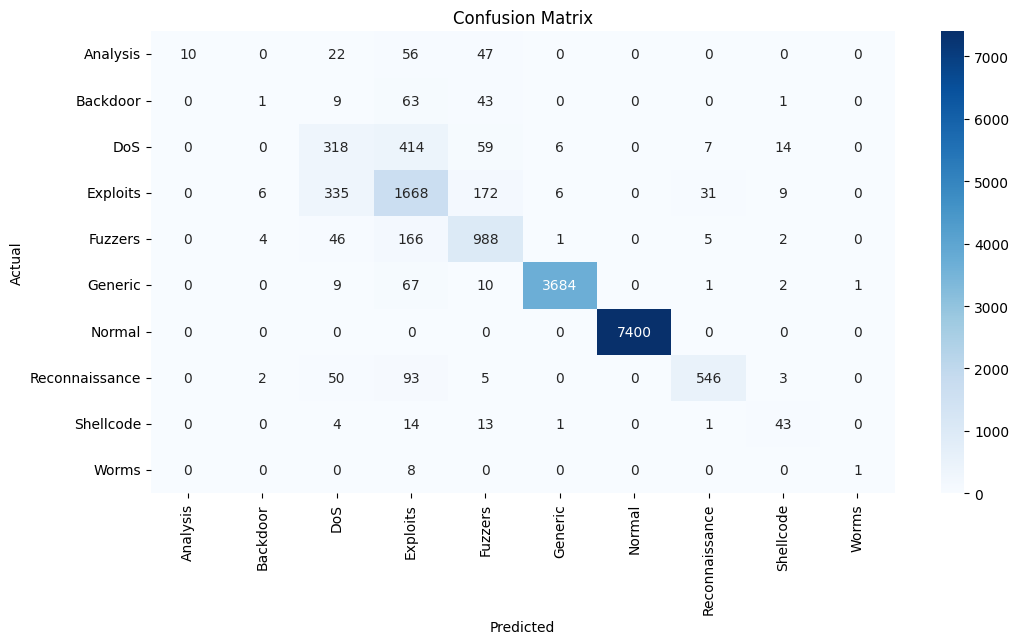

In [8]:
plt.figure(figsize=(12, 6))
sns.heatmap(confusion_matrix(y_test, y_pred),
            xticklabels=le.classes_,
            yticklabels=le.classes_,
            annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


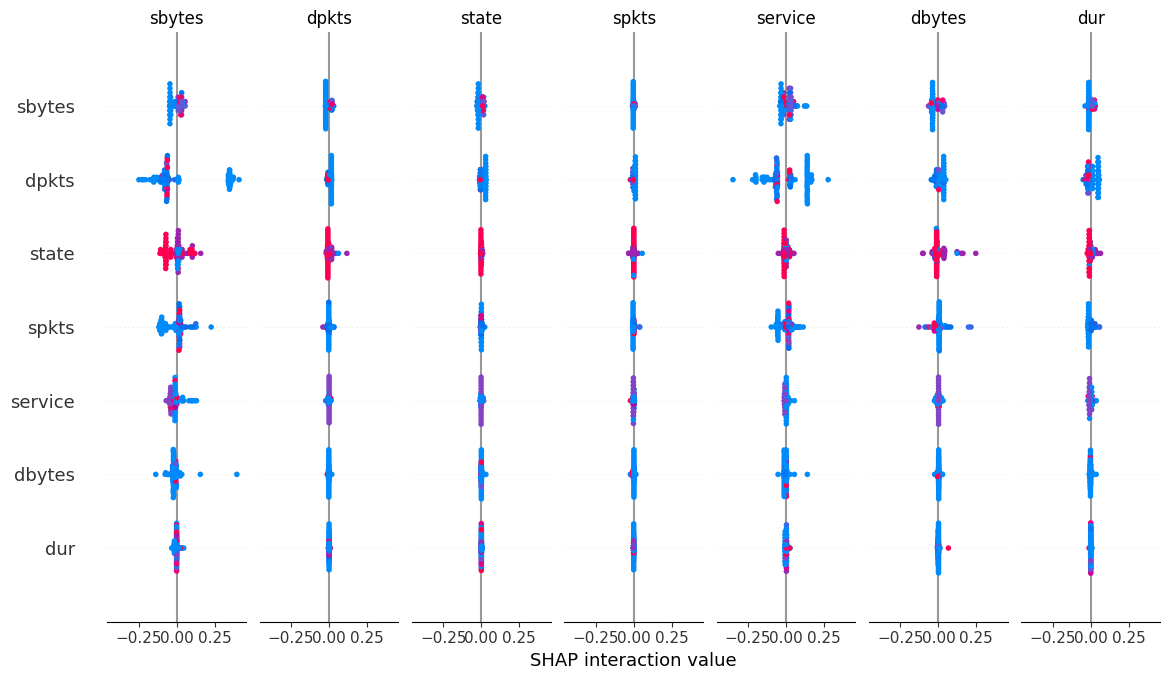

In [9]:
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test[:100])

shap.summary_plot(shap_values, X_test[:100], feature_names=X.columns)


In [10]:
with open("rf_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

with open("label_encoder.pkl", "wb") as f:
    pickle.dump(le, f)


In [11]:
# Simulated attacker behavior sequences
attacker_sequences = [
    ['Reconnaissance', 'Credential Access', 'Lateral Movement', 'Privilege Escalation'],
    ['Initial Access', 'Execution', 'Persistence'],
    ['Execution', 'Lateral Movement', 'Exfiltration'],
]

# Map TTPs to indices
all_ttps = list(set(t for seq in attacker_sequences for t in seq))
ttp_to_idx = {ttp: idx for idx, ttp in enumerate(all_ttps)}
idx_to_ttp = {idx: ttp for ttp, idx in ttp_to_idx.items()}

X_seq = []
y_seq = []

seq_length = 3

for seq in attacker_sequences:
    for i in range(len(seq) - seq_length):
        X_seq.append([ttp_to_idx[ttp] for ttp in seq[i:i+seq_length]])
        y_seq.append(ttp_to_idx[seq[i+seq_length]])

X_seq = np.array(X_seq)
y_seq = to_categorical(y_seq, num_classes=len(all_ttps))

# Build LSTM
model = Sequential()
model.add(Embedding(input_dim=len(all_ttps), output_dim=32, input_length=seq_length))
model.add(LSTM(64))
model.add(Dense(len(all_ttps), activation='softmax'))

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_seq, y_seq, epochs=30, verbose=1)


Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.0000e+00 - loss: 2.0865
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 1.0000 - loss: 2.0750
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 1.0000 - loss: 2.0636
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - accuracy: 1.0000 - loss: 2.0522
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 1.0000 - loss: 2.0407
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 1.0000 - loss: 2.0290
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 1.0000 - loss: 2.0170
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 1.0000 - loss: 2.0047
Epoch 9/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 1.0000 - loss: 1.9918
Epoch 10/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - accuracy: 1.0000 - loss: 1.9783
Epoch 11/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 1.0000 - loss: 1.9641
Epoch 12/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 1.0000 - l

In [12]:
test_sequence = ['Execution', 'Persistence', 'Lateral Movement']
test_idx = np.array([[ttp_to_idx[ttp] for ttp in test_sequence]])

pred = model.predict(test_idx)
predicted_idx = np.argmax(pred)
print("Predicted next TTP:", idx_to_ttp[predicted_idx])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step
Predicted next TTP: Privilege Escalation


In [14]:
def simulate_network_event():
    return {
        'dur': random.uniform(0.1, 5.0),
        'proto': random.choice(X['proto'].unique()),  # Use actual values from data
        'service': random.choice(X['service'].unique()), # Use actual values from data
        'state': random.choice(X['state'].unique()),   # Use actual values from data
        'spkts': random.randint(1, 100),
        'dpkts': random.randint(1, 100),
        'sbytes': random.randint(100, 5000),
        'dbytes': random.randint(100, 5000),
        'rate': random.uniform(1, 1000),
        'sttl': random.choice(X['sttl'].unique()),     # Use actual values from data
        'dttl': random.choice(X['dttl'].unique()),     # Use actual values from data
        'sload': random.uniform(1000, 100000),
        'dload': random.uniform(1000, 100000),
        'sloss': random.randint(0, 10),
        'dloss': random.randint(0, 10),
        'sinpkt': random.uniform(0, 100),
        'dinpkt': random.uniform(0, 100),
        'sjit': random.uniform(0, 100),
        'djit': random.uniform(0, 100),
        'swin': random.randint(0, 255),
        'stcpb': random.randint(0, 4294967295),
        'dtcpb': random.randint(0, 4294967295),
        'dwin': random.randint(0, 255),
        'tcprtt': random.uniform(0, 1),
        'synack': random.uniform(0, 0.5),
        'ackdat': random.uniform(0, 0.5),
        'smean': random.randint(20, 1500),
        'dmean': random.randint(20, 1500),
        'trans_depth': random.randint(0, 10),
        'response_body_len': random.randint(0, 10000),
        'ct_srv_src': random.randint(1, 50),
        'ct_state_ttl': random.choice(X['ct_state_ttl'].unique()), # Use actual values from data
        'ct_dst_ltm': random.randint(1, 50),
        'ct_src_dport_ltm': random.randint(1, 50),
        'ct_dst_sport_ltm': random.randint(1, 50),
        'ct_dst_src_ltm': random.randint(1, 50),
        'is_ftp_login': random.choice([0, 1]),
        'ct_ftp_cmd': random.randint(0, 10),
        'ct_flw_http_mthd': random.randint(0, 10),
        'ct_src_ltm': random.randint(1, 50),
        'ct_srv_dst': random.randint(1, 50),
        'is_sm_ips_ports': random.choice([0, 1]),
        'label': -1.106883 # Default value based on the data's scaling
    }

features = X.columns.tolist()

def predict_attack_rf(log_dict):
    df = pd.DataFrame([log_dict])
    # Ensure the order of columns matches the training data
    df = df[features]
    df_scaled = scaler.transform(df)
    pred = rf_model.predict(df_scaled)
    # Need to handle the case where the predicted label is not in the original training labels
    try:
        label = le.inverse_transform(pred)[0]
    except ValueError:
        label = "Unknown" # Or some other appropriate default
    return label

def simulate_response(predicted_ttp):
    if predicted_ttp in ['Privilege Escalation', 'Exfiltration']:
        print("[ACTION] Isolating host...")
    elif predicted_ttp in ['Reconnaissance']:
        print("[ACTION] Blocking scanning IP...")
    elif predicted_ttp == "Unknown":
         print("[ACTION] Further investigation needed.")
    else:
        print("[ACTION] Logging only.")

# Simulate stream
for _ in range(5):
    log = simulate_network_event()
    label = predict_attack_rf(log)
    print(f"[ALERT] Predicted TTP: {label}")
    simulate_response(label)
    time.sleep(2)

[ALERT] Predicted TTP: Normal
[ACTION] Logging only.
[ALERT] Predicted TTP: Normal
[ACTION] Logging only.
[ALERT] Predicted TTP: Normal
[ACTION] Logging only.
[ALERT] Predicted TTP: Normal
[ACTION] Logging only.
[ALERT] Predicted TTP: Normal
[ACTION] Logging only.
